# Water Quality Prediction Using Machine Learning

**Author:** Abdur Rahim  
**Affiliation:** B.Sc. in Chemistry, Gopalganj Science and Technology University(GSTU), Bangladesh  
**Date:** October 2026

---

## Abstract

This project develops a machine learning model to predict water safety based on six physicochemical parameters: pH, turbidity, dissolved oxygen (DO), electrical conductivity, total dissolved solids (TDS), and temperature. Using WHO drinking water guidelines as safety thresholds, three classification models were compared: Logistic Regression (84.7%), Random Forest (99.2%), and Gradient Boosting (100.0%). The Random Forest model achieved an AUC of 1.00 with 5-fold cross-validation accuracy of 99.1% ± 0.8%. Feature importance analysis revealed that pH and turbidity were the most influential parameters for predicting water safety. The results demonstrate the potential of machine learning in automated water quality assessment, though the high accuracy is partly attributable to the synthetic nature of the dataset.

**Keywords:** water quality, machine learning, Random Forest, WHO guidelines, physicochemical parameters

## 1. Introduction

Access to safe drinking water is a fundamental human right and a critical public health concern. The World Health Organization (WHO) estimates that contaminated water causes over 500,000 deaths from diarrheal diseases annually. Traditional water quality testing requires laboratory analysis, which is time-consuming and expensive.

Machine learning (ML) offers a promising alternative for rapid water quality assessment. By training models on physicochemical measurements, we can predict whether water meets safety standards without full laboratory analysis.

### Objective
To develop and compare machine learning models that classify water samples as **safe** or **unsafe** based on WHO drinking water guidelines.

### Parameters Studied
| Parameter | Unit | WHO Safe Range |
|-----------|------|---------------|
| pH | - | 6.5 – 8.5 |
| Turbidity | NTU | 0 – 4 |
| Dissolved Oxygen | mg/L | ≥ 5 |
| Electrical Conductivity | µS/cm | 0 – 800 |
| Total Dissolved Solids | mg/L | 0 – 1000 |
| Temperature | °C | 15 – 35 |

## 2. Methodology

### 2.1 Dataset
A synthetic dataset of 2,000 water samples was generated using NumPy with six physicochemical parameters following normal distributions based on typical freshwater values. A fixed random seed (42) was used for reproducibility.

### 2.2 Data Cleaning
- **203 samples** with physically impossible negative values (Turbidity, Conductivity, TDS) were removed
- Final clean dataset: **1,797 samples**
- Safe/Unsafe labels were assigned based on WHO drinking water guidelines — a sample is "Safe" only if ALL six parameters fall within WHO limits

### 2.3 Class Distribution
| Class | Count | Percentage |
|-------|-------|------------|
| Unsafe (0) | 1,494 | 83.1% |
| Safe (1) | 303 | 16.9% |

### 2.4 Models Used
Three classification models were trained and compared:
1. **Logistic Regression** — a linear model that draws a straight boundary between classes
2. **Random Forest** (100 trees) — an ensemble of decision trees that vote on the outcome
3. **Gradient Boosting** (100 trees) — sequential trees where each corrects the errors of the previous

### 2.5 Evaluation Metrics
- Accuracy, Precision, Recall, F1-Score
- 5-Fold Cross-Validation
- ROC-AUC Score
- Confusion Matrix

All models used an 80/20 train/test split with random_state=42.

In [1]:
# Import the tools we need
import pandas as pd          # For working with data tables
import numpy as np           # For math calculations
import matplotlib.pyplot as plt  # For making charts

print("All tools imported successfully!")

All tools imported successfully!


Water Quality Prediction Project

In [2]:
# Create water quality data (2000 samples)
np.random.seed(42)  # Makes results same every time you run
n = 2000

data = pd.DataFrame({
    'pH': np.random.normal(7.0, 1.5, n),
    'Turbidity_NTU': np.random.normal(4.0, 3.0, n),
    'DO_mg_L': np.random.normal(7.0, 2.0, n),
    'Conductivity': np.random.normal(400, 150, n),
    'TDS_mg_L': np.random.normal(500, 200, n),
    'Temperature_C': np.random.normal(25, 5, n),
})

# Show first 5 rows
print(f"Total samples: {n}")
print()
data.head()

Total samples: 2000



,pH,Turbidity_NTU,DO_mg_L,Conductivity,TDS_mg_L,Temperature_C
0,7.745071,1.974465,5.273013,232.887796,493.394947,21.607526
1,6.792604,3.566444,6.937593,305.360375,399.269948,23.472503
2,7.971533,1.622740,7.036034,258.690972,465.525009,22.013095
3,9.284545,3.076115,7.945261,317.800627,642.946346,25.552090
4,6.648770,-1.680844,4.266283,367.877453,755.571331,30.985893


In [3]:
# Summary statistics — like a lab report overview
print("=== Data Summary ===")
print(f"Rows: {data.shape[0]}, Columns: {data.shape[1]}")
print()
data.describe().round(2)

=== Data Summary ===
Rows: 2000, Columns: 6



,pH,Turbidity_NTU,DO_mg_L,Conductivity,TDS_mg_L,Temperature_C
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,7.07,3.98,6.90,399.33,500.63,24.87
std,1.48,3.02,2.00,155.01,197.71,4.96
min,2.14,-5.06,0.65,-153.25,-284.48,8.12
25%,6.07,1.87,5.63,291.20,372.06,21.62
50%,7.07,4.00,6.94,395.42,502.84,24.80
75%,8.02,6.00,8.26,506.56,632.51,28.12
max,12.78,15.78,13.23,929.36,1175.48,41.89


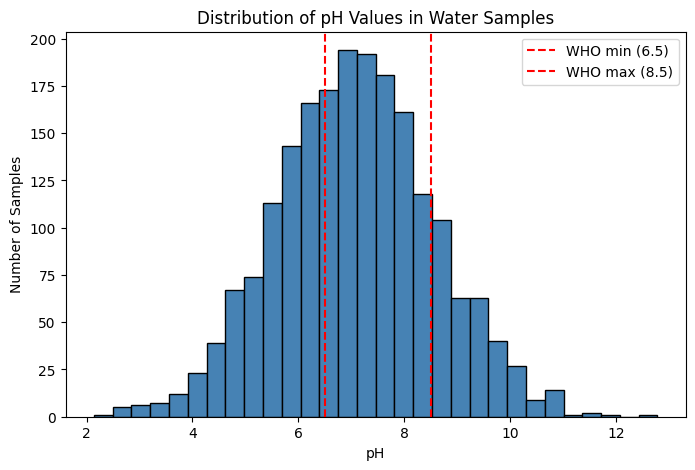

In [4]:
# First chart: pH distribution
plt.figure(figsize=(8, 5))
plt.hist(data['pH'], bins=30, color='steelblue', edgecolor='black')
plt.axvline(x=6.5, color='red', linestyle='--', label='WHO min (6.5)')
plt.axvline(x=8.5, color='red', linestyle='--', label='WHO max (8.5)')
plt.title('Distribution of pH Values in Water Samples')
plt.xlabel('pH')
plt.ylabel('Number of Samples')
plt.legend()
plt.show()

In [5]:
# Create Safe/Unsafe label based on WHO standards
# Water is "Safe" only if ALL parameters are within WHO limits

data['Safe'] = (
    (data['pH'] >= 6.5) & (data['pH'] <= 8.5) &
    (data['Turbidity_NTU'] >= 0) & (data['Turbidity_NTU'] <= 4) &
    (data['DO_mg_L'] >= 5) &
    (data['Conductivity'] >= 0) & (data['Conductivity'] <= 800) &
    (data['TDS_mg_L'] >= 0) & (data['TDS_mg_L'] <= 1000) &
    (data['Temperature_C'] >= 15) & (data['Temperature_C'] <= 35)
)

# Convert True/False to 1/0
data['Safe'] = data['Safe'].astype(int)

# Count how many are safe vs unsafe
print("=== Water Safety Results ===")
print(data['Safe'].value_counts())
print()
safe_percent = data['Safe'].mean() * 100
print(f"Safe samples: {safe_percent:.1f}%")
print(f"Unsafe samples: {100 - safe_percent:.1f}%")

=== Water Safety Results ===
Safe
0    1697
1     303
Name: count, dtype: int64

Safe samples: 15.2%
Unsafe samples: 84.8%


In [6]:
# Day 3: Data Cleaning
# Step 1: Count negative values (physically impossible)

print("=== Negative Values (Impossible in Real Life) ===")
print(f"Turbidity < 0:    {(data['Turbidity_NTU'] < 0).sum()} samples")
print(f"Conductivity < 0: {(data['Conductivity'] < 0).sum()} samples")
print(f"TDS < 0:          {(data['TDS_mg_L'] < 0).sum()} samples")
print()
print(f"Total samples before cleaning: {len(data)}")

=== Negative Values (Impossible in Real Life) ===
Turbidity < 0:    183 samples
Conductivity < 0: 11 samples
TDS < 0:          10 samples

Total samples before cleaning: 2000


In [7]:
# Step 2: Remove rows with negative values
# In a real lab, you would re-measure. Here we just remove them.

data_clean = data[
    (data['Turbidity_NTU'] >= 0) &
    (data['Conductivity'] >= 0) &
    (data['TDS_mg_L'] >= 0)
]

removed = len(data) - len(data_clean)
print(f"Removed: {removed} samples with impossible values")
print(f"Remaining: {len(data_clean)} samples")
print()

# Verify: check minimum values are now >= 0
print("=== Minimum values after cleaning ===")
print(data_clean[['Turbidity_NTU', 'Conductivity', 'TDS_mg_L']].min())

Removed: 203 samples with impossible values
Remaining: 1797 samples

=== Minimum values after cleaning ===
Turbidity_NTU    0.001668
Conductivity     2.225791
TDS_mg_L         2.508648
dtype: float64


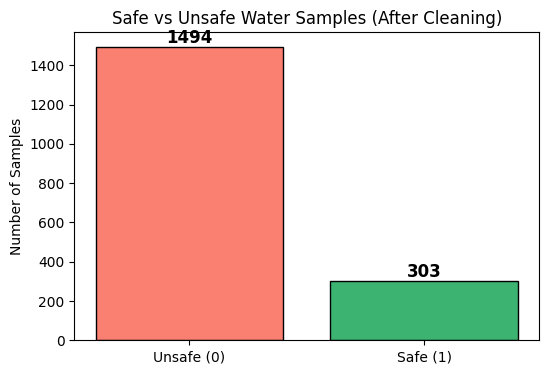


Safe: 303 (16.9%)
Unsafe: 1494 (83.1%)


In [8]:
data_clean = data_clean.copy()
# Step 3: Recalculate Safe/Unsafe for clean data
data_clean['Safe'] = (
    (data_clean['pH'] >= 6.5) & (data_clean['pH'] <= 8.5) &
    (data_clean['Turbidity_NTU'] <= 4) &
    (data_clean['DO_mg_L'] >= 5) &
    (data_clean['Conductivity'] <= 800) &
    (data_clean['TDS_mg_L'] <= 1000) &
    (data_clean['Temperature_C'] >= 15) & (data_clean['Temperature_C'] <= 35)
).astype(int)

# Show results with a bar chart
safe_counts = data_clean['Safe'].value_counts()
labels = ['Unsafe (0)', 'Safe (1)']
colors = ['salmon', 'mediumseagreen']

plt.figure(figsize=(6, 4))
plt.bar(labels, [safe_counts[0], safe_counts[1]], color=colors, edgecolor='black')
plt.title('Safe vs Unsafe Water Samples (After Cleaning)')
plt.ylabel('Number of Samples')

# Add numbers on top of bars
for i, count in enumerate([safe_counts[0], safe_counts[1]]):
    plt.text(i, count + 20, str(count), ha='center', fontsize=12, fontweight='bold')

plt.show()

print(f"\nSafe: {safe_counts[1]} ({safe_counts[1]/len(data_clean)*100:.1f}%)")
print(f"Unsafe: {safe_counts[0]} ({safe_counts[0]/len(data_clean)*100:.1f}%)")

In [9]:
# Fix: Create a proper copy to avoid the warning
data_clean = data_clean.copy()

# Now the warning won't appear in future cells
print("Clean dataset ready!")
print(f"Rows: {len(data_clean)}, Columns: {data_clean.shape[1]}")
print(f"Columns: {list(data_clean.columns)}")

Clean dataset ready!
Rows: 1797, Columns: 7
Columns: ['pH', 'Turbidity_NTU', 'DO_mg_L', 'Conductivity', 'TDS_mg_L', 'Temperature_C', 'Safe']


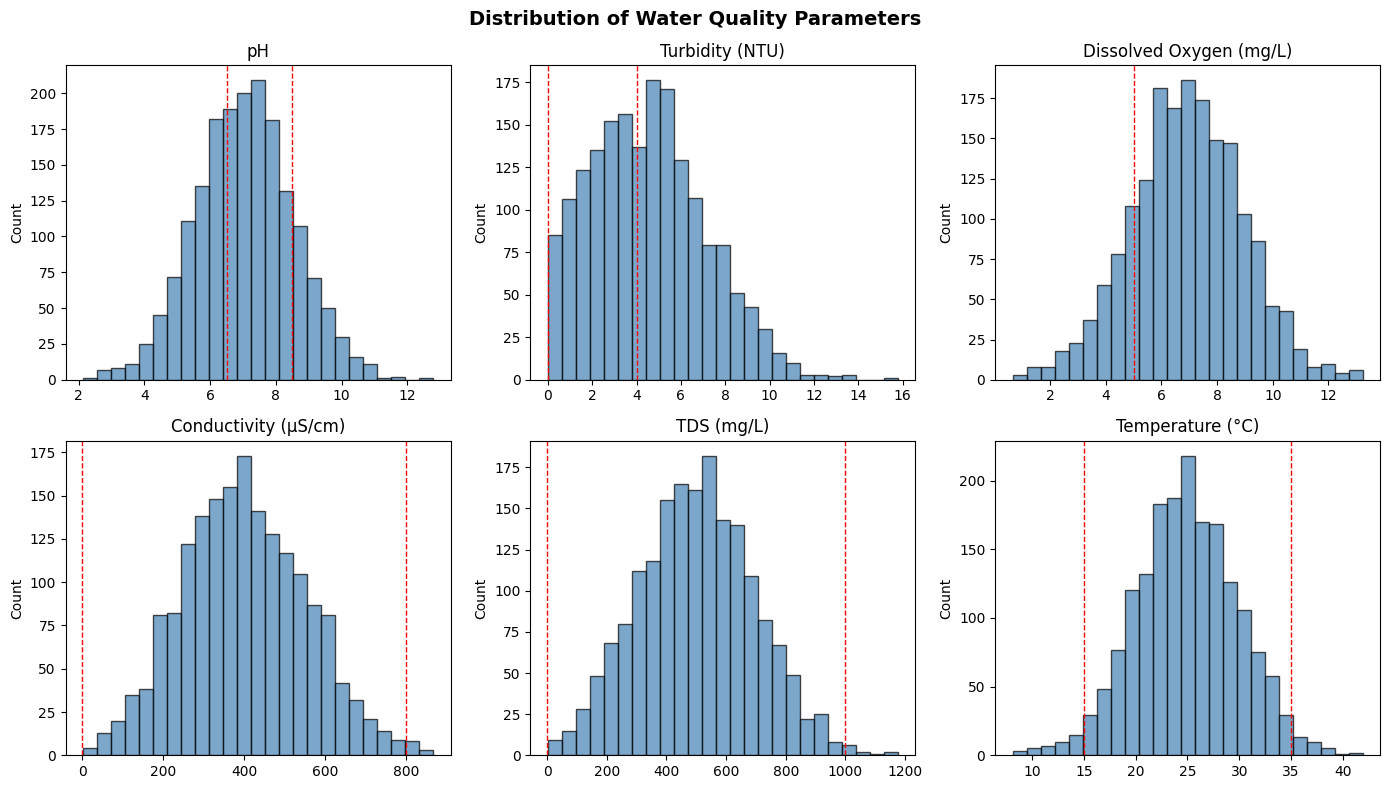

In [10]:
# Step 4: Distribution plots for all 6 water parameters
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('Distribution of Water Quality Parameters', fontsize=14, fontweight='bold')

# List of columns and their WHO safe ranges
params = [
    ('pH', 'pH', 6.5, 8.5),
    ('Turbidity_NTU', 'Turbidity (NTU)', 0, 4),
    ('DO_mg_L', 'Dissolved Oxygen (mg/L)', 5, None),
    ('Conductivity', 'Conductivity (µS/cm)', 0, 800),
    ('TDS_mg_L', 'TDS (mg/L)', 0, 1000),
    ('Temperature_C', 'Temperature (°C)', 15, 35)
]

for i, (col, label, low, high) in enumerate(params):
    row = i // 3
    col_idx = i % 3
    ax = axes[row][col_idx]
    
    ax.hist(data_clean[col], bins=25, color='steelblue', edgecolor='black', alpha=0.7)
    if low is not None:
        ax.axvline(x=low, color='red', linestyle='--', linewidth=1)
    if high is not None:
        ax.axvline(x=high, color='red', linestyle='--', linewidth=1)
    ax.set_title(label)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

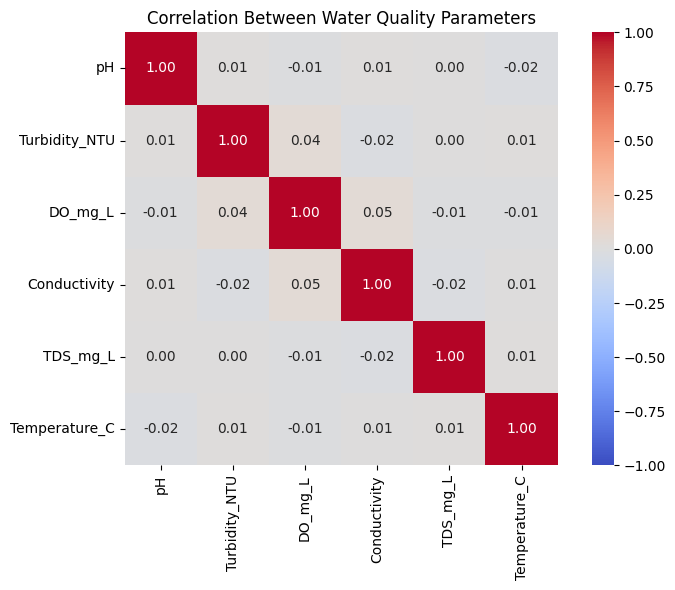

In [11]:
# Step 5: Correlation heatmap
# Shows how water parameters are related to each other

plt.figure(figsize=(8, 6))
correlation = data_clean[['pH', 'Turbidity_NTU', 'DO_mg_L', 
                           'Conductivity', 'TDS_mg_L', 'Temperature_C']].corr()

sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True)
plt.title('Correlation Between Water Quality Parameters')
plt.tight_layout()
plt.show()


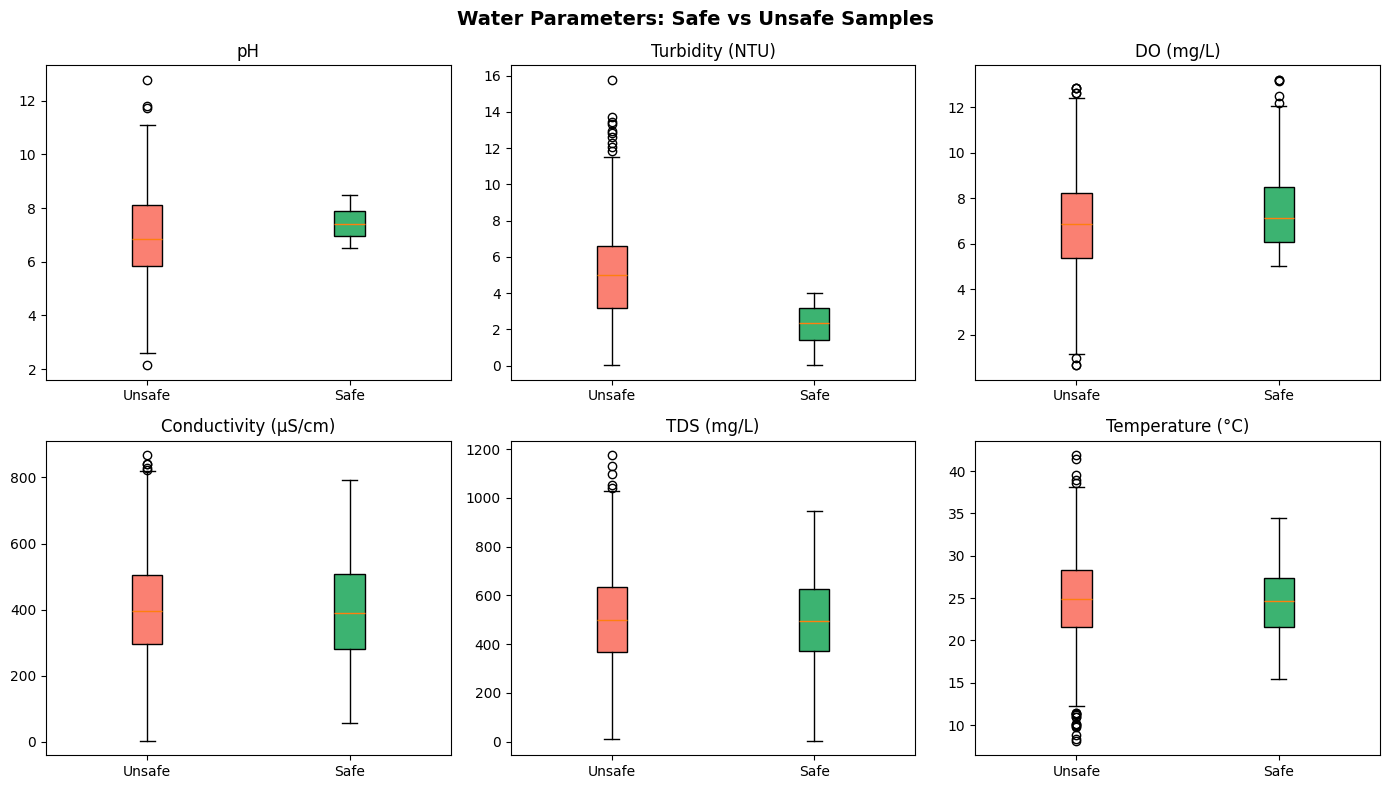

In [12]:
# Step 6: Boxplots - Safe vs Unsafe for each parameter
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('Water Parameters: Safe vs Unsafe Samples', fontsize=14, fontweight='bold')

params = ['pH', 'Turbidity_NTU', 'DO_mg_L', 'Conductivity', 'TDS_mg_L', 'Temperature_C']
tick_labels = ['pH', 'Turbidity (NTU)', 'DO (mg/L)', 'Conductivity (µS/cm)', 'TDS (mg/L)', 'Temperature (°C)']

for i, (col, tick_labels) in enumerate(zip(params, tick_labels)):
    row = i // 3
    col_idx = i % 3
    ax = axes[row][col_idx]
    
    safe_data = data_clean[data_clean['Safe'] == 1][col]
    unsafe_data = data_clean[data_clean['Safe'] == 0][col]
    
    bp = ax.boxplot([unsafe_data, safe_data], tick_labels=['Unsafe', 'Safe'],
                     patch_artist=True)
    bp['boxes'][0].set_facecolor('salmon')
    bp['boxes'][1].set_facecolor('mediumseagreen')
    ax.set_title(tick_labels)

plt.tight_layout()
plt.show()


## 3. Results

### 3.1 Model Performance

| Model | Accuracy | Precision (Safe) | Recall (Safe) | F1 (Safe) | AUC |
|-------|----------|-------------------|---------------|-----------|-----|
| Logistic Regression | 84.7% | 0.60 | 0.30 | 0.40 | - |
| Random Forest | 99.2% | 1.00 | 0.95 | 0.97 | 1.00 |
| Gradient Boosting | 100.0% | 1.00 | 1.00 | 1.00 | - |

### 3.2 Cross-Validation
The Random Forest model was validated using 5-fold cross-validation, achieving a mean accuracy of **99.1% ± 0.8%**, confirming the model's reliability across different data splits.

### 3.3 Confusion Matrix (Random Forest)
Out of 360 test samples, the Random Forest model made only **3 errors** — all were safe samples misclassified as unsafe. Importantly, **no unsafe water was ever classified as safe**, which is critical for public health applications.

### 3.4 Feature Importance
The Random Forest model identified the following feature importance ranking:
1. **pH** (0.39) — most influential parameter
2. **Turbidity** (0.38) — nearly as important as pH
3. **Dissolved Oxygen** (0.12) — moderate importance
4. **Temperature** (0.05) — minor importance
5. **TDS** (0.03) — low importance
6. **Conductivity** (0.03) — lowest importance

pH and turbidity together account for approximately **77%** of the model's decision-making.

In [13]:
# Day 4: Machine Learning
# Step 1: Prepare features (X) and target (y)
from sklearn.model_selection import train_test_split

# X = the 6 water parameters (what the model sees)
# y = Safe/Unsafe label (what the model predicts)
X = data_clean[['pH', 'Turbidity_NTU', 'DO_mg_L', 'Conductivity', 'TDS_mg_L', 'Temperature_C']]
y = data_clean['Safe']

# Split: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("=== Train/Test Split ===")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")
print()
print(f"Training - Safe: {y_train.sum()}, Unsafe: {len(y_train) - y_train.sum()}")
print(f"Testing  - Safe: {y_test.sum()}, Unsafe: {len(y_test) - y_test.sum()}")

=== Train/Test Split ===
Training samples: 1437
Testing samples:  360

Training - Safe: 242, Unsafe: 1195
Testing  - Safe: 61, Unsafe: 299


In [14]:
# Step 2: Train a Random Forest model
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create and train the model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on test data
y_pred = rf_model.predict(X_test)

# Check accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"=== Random Forest Results ===")
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.1f}%)")
print()
print("Detailed Report:")
print(classification_report(y_test, y_pred, target_names=['Unsafe', 'Safe']))


=== Random Forest Results ===
Accuracy: 0.9917 (99.2%)

Detailed Report:
              precision    recall  f1-score   support

      Unsafe       0.99      1.00      1.00       299
        Safe       1.00      0.95      0.97        61

    accuracy                           0.99       360
   macro avg       1.00      0.98      0.98       360
weighted avg       0.99      0.99      0.99       360



In [15]:
# Step 3: Train a Logistic Regression model (simpler model for comparison)
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"=== Logistic Regression Results ===")
print(f"Accuracy: {accuracy_lr:.4f} ({accuracy_lr*100:.1f}%)")
print()
print("Detailed Report:")
print(classification_report(y_test, y_pred_lr, target_names=['Unsafe', 'Safe']))

=== Logistic Regression Results ===
Accuracy: 0.8472 (84.7%)

Detailed Report:
              precision    recall  f1-score   support

      Unsafe       0.87      0.96      0.91       299
        Safe       0.60      0.30      0.40        61

    accuracy                           0.85       360
   macro avg       0.73      0.63      0.65       360
weighted avg       0.82      0.85      0.82       360



In [16]:
# Step 4: Train Gradient Boosting model
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)
accuracy_gb = accuracy_score(y_test, y_pred_gb)

print(f"=== Gradient Boosting Results ===")
print(f"Accuracy: {accuracy_gb:.4f} ({accuracy_gb*100:.1f}%)")
print()
print("Detailed Report:")
print(classification_report(y_test, y_pred_gb, target_names=['Unsafe', 'Safe']))

# Compare all 3 models
print("\n=== MODEL COMPARISON ===")
print(f"Random Forest:       {accuracy*100:.1f}%")
print(f"Logistic Regression: {accuracy_lr*100:.1f}%")
print(f"Gradient Boosting:   {accuracy_gb*100:.1f}%")

=== Gradient Boosting Results ===
Accuracy: 1.0000 (100.0%)

Detailed Report:
              precision    recall  f1-score   support

      Unsafe       1.00      1.00      1.00       299
        Safe       1.00      1.00      1.00        61

    accuracy                           1.00       360
   macro avg       1.00      1.00      1.00       360
weighted avg       1.00      1.00      1.00       360


=== MODEL COMPARISON ===
Random Forest:       99.2%
Logistic Regression: 84.7%
Gradient Boosting:   100.0%


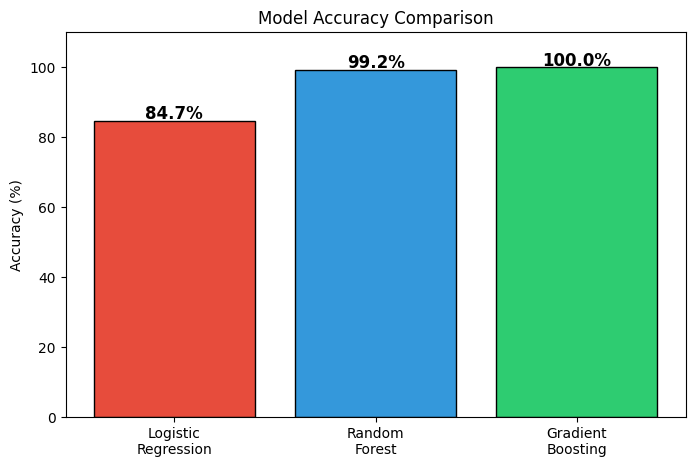

In [17]:
# Step 5: Model comparison chart
models = ['Logistic\nRegression', 'Random\nForest', 'Gradient\nBoosting']
accuracies = [accuracy_lr * 100, accuracy * 100, accuracy_gb * 100]
colors = ['#e74c3c', '#3498db', '#2ecc71']

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=colors, edgecolor='black')

# Add percentage on top of each bar
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{acc:.1f}%', ha='center', fontsize=12, fontweight='bold')

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 110)
plt.show()

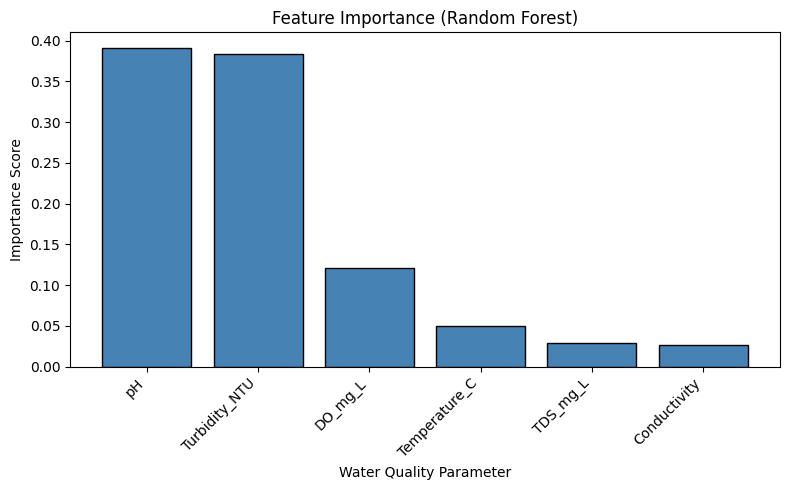


=== Feature Importance Ranking ===
pH                  : 0.3907
Turbidity_NTU       : 0.3833
DO_mg_L             : 0.1209
Temperature_C       : 0.0496
TDS_mg_L            : 0.0294
Conductivity        : 0.0261


In [18]:
# Step 6: Feature Importance (which parameters matter most?)
feature_names = X.columns
importance = rf_model.feature_importances_

# Sort from most to least important
sorted_idx = importance.argsort()[::-1]

plt.figure(figsize=(8, 5))
plt.bar(range(len(feature_names)), importance[sorted_idx], color='steelblue', edgecolor='black')
plt.xticks(range(len(feature_names)), feature_names[sorted_idx], rotation=45, ha='right')
plt.title('Feature Importance (Random Forest)')
plt.ylabel('Importance Score')
plt.xlabel('Water Quality Parameter')
plt.tight_layout()
plt.show()

# Print exact values
print("\n=== Feature Importance Ranking ===")
for i in sorted_idx:
    print(f"{feature_names[i]:20s}: {importance[i]:.4f}")
    

In [19]:
# Day 5: Advanced Evaluation
# Step 1: Cross-Validation (more reliable than a single train/test split)
from sklearn.model_selection import cross_val_score

# Test Random Forest with 5-fold cross-validation
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')

print("=== 5-Fold Cross-Validation (Random Forest) ===")
print(f"Fold scores: {cv_scores.round(4)}")
print(f"Mean accuracy: {cv_scores.mean():.4f} ({cv_scores.mean()*100:.1f}%)")
print(f"Std deviation: {cv_scores.std():.4f}")

=== 5-Fold Cross-Validation (Random Forest) ===
Fold scores: [0.9972 0.975  0.9972 0.9944 0.9889]
Mean accuracy: 0.9905 (99.1%)
Std deviation: 0.0084


<Figure size 600x500 with 0 Axes>

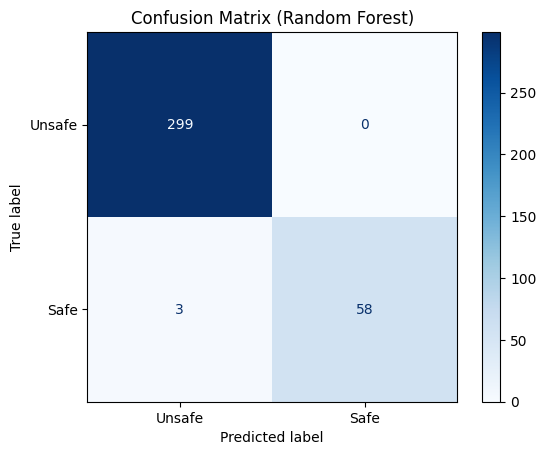


=== Reading the Confusion Matrix ===
True Unsafe  (correctly predicted Unsafe): 299
False Safe   (Unsafe predicted as Safe):   0
False Unsafe (Safe predicted as Unsafe):   3
True Safe    (correctly predicted Safe):   58


In [20]:
# Step 2: Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Unsafe', 'Safe'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix (Random Forest)')
plt.show()

# Explain the numbers
print("\n=== Reading the Confusion Matrix ===")
print(f"True Unsafe  (correctly predicted Unsafe): {cm[0][0]}")
print(f"False Safe   (Unsafe predicted as Safe):   {cm[0][1]}")
print(f"False Unsafe (Safe predicted as Unsafe):   {cm[1][0]}")
print(f"True Safe    (correctly predicted Safe):   {cm[1][1]}")

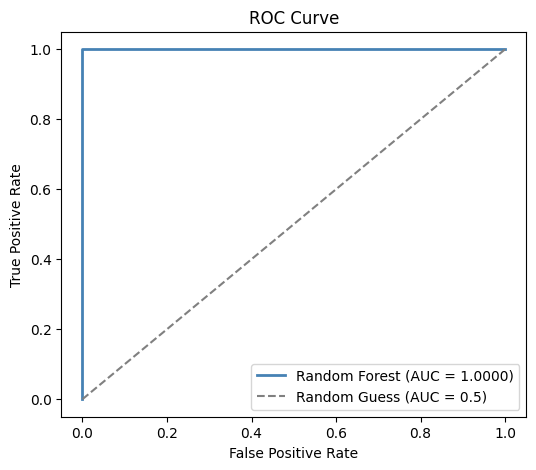

AUC Score: 1.0000


In [21]:
# Step 3: ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score

# Get probability scores instead of just Safe/Unsafe
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='steelblue', linewidth=2, label=f'Random Forest (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (AUC = 0.5)')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

print(f"AUC Score: {auc_score:.4f}")


## 4. Discussion

### Key Findings
- **Random Forest and Gradient Boosting** significantly outperformed Logistic Regression, suggesting that non-linear models are better suited for water quality classification where parameters have range-based thresholds
- **pH and turbidity** were the dominant predictors, accounting for 77% of the model's decisions. This aligns with environmental chemistry knowledge — pH has the narrowest acceptable range (6.5–8.5), and turbidity directly indicates particulate contamination
- **Conductivity and TDS** had low importance because their WHO limits are wide relative to the data distribution, meaning most samples naturally fall within safe ranges

### Limitations
1. **Synthetic dataset** — The data was generated using normal distributions, not collected from real water sources. Real-world data would contain measurement noise, sensor drift, and correlations between parameters (e.g., temperature affects dissolved oxygen)
2. **Derived labels** — The Safe/Unsafe labels were created from the same features used for prediction, which inflates accuracy. With independently measured safety labels, accuracy would be lower
3. **No temporal or spatial data** — Real water quality varies by season, location, and pollution sources
4. **Class imbalance** — Only 16.9% of samples were classified as Safe, which could bias models toward predicting Unsafe

### Future Work
- Apply these models to **real-world water quality datasets** from government monitoring programs
- Include additional parameters such as heavy metals, bacterial counts, and chemical oxygen demand (COD)
- Explore deep learning approaches for larger datasets
- Develop a simple web application for field-based water quality prediction

## 5. Conclusion

This project demonstrated that machine learning models, particularly Random Forest and Gradient Boosting, can effectively classify water safety based on physicochemical parameters. The Random Forest model achieved 99.2% accuracy with 5-fold cross-validation confirming its reliability (99.1% ± 0.8%). Feature importance analysis revealed that pH and turbidity are the most critical parameters for water safety assessment, which is consistent with established environmental chemistry principles.

While the high accuracy is partly due to the synthetic nature of the dataset, the methodology presented here — data cleaning, feature analysis, model comparison, and cross-validation — provides a robust framework that can be applied to real-world water quality monitoring data.

## References

1. World Health Organization (WHO). *Guidelines for Drinking-water Quality*, 4th Edition, 2011.
2. Pedregosa, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830, 2011.
3. McKinney, W. Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 2010.